# ¿Vender más significa ganar más?
## Un mes en la tienda Conecta
Conecta vende veinte productos de tecnología. Al terminar septiembre, su administradora quiere saber cuánto vendió, qué parte quedó después de pagar los productos y en cuáles debería concentrar su atención.

Tu equipo debe preparar una recomendación basada en datos. Primero reconocerás la información con un análisis resuelto; después completarás tres tareas breves.

**Nombre(s):** escribe aquí.  
**Entrega:** este cuaderno con las celdas completadas, sus resultados y las respuestas escritas. Ejecuta las celdas en orden con **Shift + Enter**.

Los datos son **simulados con fines educativos**. Cada fila representa una venta de un único producto, que puede incluir varias unidades. Los valores monetarios están en **pesos colombianos (COP), sin IVA**. No hay devoluciones, cancelaciones, fletes ni gastos operativos. Los costos unitarios son los costos asignados a las unidades vendidas.

El cuaderno incluye los datos y funciona sin descargar archivos externos. Requiere pandas, numpy, seaborn y matplotlib, disponibles normalmente en Colab.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from io import StringIO
from IPython.display import display

sns.set_theme(style="whitegrid", palette="colorblind")
pd.options.display.float_format = "{:,.2f}".format

## Reconocer el negocio
Cargamos las ventas y comprobamos el período, el tamaño y la calidad de la tabla. La carga está resuelta: la actividad comienza al interpretar los registros.

In [2]:
CSV_VENTAS = 'venta_id,fecha,producto_id,producto,canal,unidades,precio_unitario,costo_unitario,descuento_pct\r\nV001,2026-09-01,P13,Cargador,Tienda,1,70000,28000,5\r\nV002,2026-09-02,P01,Portátil,Tienda,2,2400000,2160000,5\r\nV003,2026-09-02,P06,Mouse,Tienda,5,80000,32000,5\r\nV004,2026-09-02,P08,Webcam,Web,1,200000,100000,0\r\nV005,2026-09-02,P11,Router,Tienda,2,220000,143000,10\r\nV006,2026-09-03,P01,Portátil,Tienda,5,2400000,2160000,0\r\nV007,2026-09-03,P03,Teléfono,Tienda,4,1500000,1275000,0\r\nV008,2026-09-03,P03,Teléfono,Tienda,6,1500000,1275000,5\r\nV009,2026-09-03,P03,Teléfono,Tienda,4,1500000,1275000,5\r\nV010,2026-09-03,P05,Teclado,Tienda,6,130000,65000,0\r\nV011,2026-09-03,P06,Mouse,Web,5,80000,32000,5\r\nV012,2026-09-03,P06,Mouse,Tienda,1,80000,32000,0\r\nV013,2026-09-03,P11,Router,Web,1,220000,143000,10\r\nV014,2026-09-03,P12,Parlante,Web,1,150000,75000,0\r\nV015,2026-09-03,P14,Cable HDMI,Web,1,35000,10500,0\r\nV016,2026-09-03,P19,Adaptador,Tienda,1,50000,20000,0\r\nV017,2026-09-03,P20,Limpiador,Tienda,2,25000,7500,0\r\nV018,2026-09-03,P20,Limpiador,Web,2,25000,7500,5\r\nV019,2026-09-04,P01,Portátil,Tienda,6,2400000,2160000,10\r\nV020,2026-09-04,P01,Portátil,Web,5,2400000,2160000,5\r\nV021,2026-09-04,P02,Monitor,Web,6,850000,595000,10\r\nV022,2026-09-04,P08,Webcam,Web,2,200000,100000,0\r\nV023,2026-09-04,P08,Webcam,Web,1,200000,100000,5\r\nV024,2026-09-04,P14,Cable HDMI,Web,4,35000,10500,5\r\nV025,2026-09-04,P16,Hub USB,Tienda,1,110000,55000,5\r\nV026,2026-09-04,P16,Hub USB,Tienda,1,110000,55000,0\r\nV027,2026-09-04,P19,Adaptador,Tienda,2,50000,20000,0\r\nV028,2026-09-05,P10,Memoria USB,Tienda,3,45000,18000,0\r\nV029,2026-09-05,P11,Router,Tienda,2,220000,143000,10\r\nV030,2026-09-05,P18,Funda,Web,2,60000,24000,0\r\nV031,2026-09-06,P02,Monitor,Web,5,850000,595000,0\r\nV032,2026-09-06,P04,Tableta,Web,6,1100000,825000,0\r\nV033,2026-09-06,P06,Mouse,Web,8,80000,32000,10\r\nV034,2026-09-06,P07,Audífonos,Web,2,180000,90000,10\r\nV035,2026-09-06,P07,Audífonos,Tienda,1,180000,90000,10\r\nV036,2026-09-06,P10,Memoria USB,Web,6,45000,18000,0\r\nV037,2026-09-06,P13,Cargador,Tienda,1,70000,28000,0\r\nV038,2026-09-06,P18,Funda,Tienda,2,60000,24000,10\r\nV039,2026-09-06,P20,Limpiador,Web,2,25000,7500,10\r\nV040,2026-09-07,P04,Tableta,Web,6,1100000,825000,0\r\nV041,2026-09-07,P05,Teclado,Web,2,130000,65000,0\r\nV042,2026-09-07,P09,Disco SSD,Web,1,300000,195000,10\r\nV043,2026-09-07,P13,Cargador,Tienda,4,70000,28000,0\r\nV044,2026-09-08,P03,Teléfono,Tienda,2,1500000,1275000,0\r\nV045,2026-09-08,P07,Audífonos,Tienda,2,180000,90000,10\r\nV046,2026-09-08,P07,Audífonos,Tienda,2,180000,90000,0\r\nV047,2026-09-08,P11,Router,Web,1,220000,143000,5\r\nV048,2026-09-08,P13,Cargador,Tienda,2,70000,28000,0\r\nV049,2026-09-08,P13,Cargador,Tienda,3,70000,28000,10\r\nV050,2026-09-08,P15,Soporte portátil,Web,1,90000,36000,10\r\nV051,2026-09-08,P15,Soporte portátil,Web,2,90000,36000,10\r\nV052,2026-09-08,P17,Alfombrilla,Web,1,30000,9000,0\r\nV053,2026-09-08,P18,Funda,Tienda,2,60000,24000,10\r\nV054,2026-09-08,P18,Funda,Tienda,1,60000,24000,0\r\nV055,2026-09-08,P19,Adaptador,Web,2,50000,20000,5\r\nV056,2026-09-09,P03,Teléfono,Web,4,1500000,1275000,0\r\nV057,2026-09-09,P05,Teclado,Web,2,130000,65000,0\r\nV058,2026-09-09,P15,Soporte portátil,Web,1,90000,36000,0\r\nV059,2026-09-09,P17,Alfombrilla,Tienda,1,30000,9000,0\r\nV060,2026-09-09,P17,Alfombrilla,Web,2,30000,9000,0\r\nV061,2026-09-09,P18,Funda,Tienda,2,60000,24000,0\r\nV062,2026-09-10,P04,Tableta,Web,3,1100000,825000,10\r\nV063,2026-09-10,P06,Mouse,Web,3,80000,32000,0\r\nV064,2026-09-10,P09,Disco SSD,Web,1,300000,195000,5\r\nV065,2026-09-10,P09,Disco SSD,Tienda,2,300000,195000,10\r\nV066,2026-09-10,P16,Hub USB,Tienda,1,110000,55000,10\r\nV067,2026-09-10,P16,Hub USB,Web,1,110000,55000,0\r\nV068,2026-09-10,P17,Alfombrilla,Tienda,2,30000,9000,0\r\nV069,2026-09-11,P03,Teléfono,Tienda,4,1500000,1275000,0\r\nV070,2026-09-11,P05,Teclado,Tienda,2,130000,65000,0\r\nV071,2026-09-11,P11,Router,Tienda,1,220000,143000,0\r\nV072,2026-09-11,P11,Router,Web,1,220000,143000,10\r\nV073,2026-09-11,P15,Soporte portátil,Tienda,1,90000,36000,10\r\nV074,2026-09-11,P17,Alfombrilla,Tienda,2,30000,9000,0\r\nV075,2026-09-11,P20,Limpiador,Web,2,25000,7500,10\r\nV076,2026-09-12,P07,Audífonos,Web,1,180000,90000,0\r\nV077,2026-09-12,P12,Parlante,Web,2,150000,75000,10\r\nV078,2026-09-12,P14,Cable HDMI,Web,4,35000,10500,5\r\nV079,2026-09-13,P01,Portátil,Web,4,2400000,2160000,10\r\nV080,2026-09-13,P02,Monitor,Web,9,850000,595000,5\r\nV081,2026-09-13,P03,Teléfono,Web,6,1500000,1275000,10\r\nV082,2026-09-13,P04,Tableta,Web,3,1100000,825000,10\r\nV083,2026-09-13,P05,Teclado,Tienda,2,130000,65000,0\r\nV084,2026-09-13,P07,Audífonos,Web,2,180000,90000,5\r\nV085,2026-09-13,P09,Disco SSD,Web,2,300000,195000,0\r\nV086,2026-09-13,P09,Disco SSD,Tienda,2,300000,195000,5\r\nV087,2026-09-13,P11,Router,Tienda,1,220000,143000,10\r\nV088,2026-09-13,P12,Parlante,Web,1,150000,75000,10\r\nV089,2026-09-14,P04,Tableta,Tienda,3,1100000,825000,5\r\nV090,2026-09-14,P04,Tableta,Web,3,1100000,825000,10\r\nV091,2026-09-14,P05,Teclado,Web,3,130000,65000,5\r\nV092,2026-09-14,P06,Mouse,Tienda,6,80000,32000,0\r\nV093,2026-09-14,P08,Webcam,Tienda,1,200000,100000,5\r\nV094,2026-09-14,P12,Parlante,Web,1,150000,75000,0\r\nV095,2026-09-14,P14,Cable HDMI,Tienda,3,35000,10500,5\r\nV096,2026-09-14,P14,Cable HDMI,Web,1,35000,10500,5\r\nV097,2026-09-14,P20,Limpiador,Web,3,25000,7500,5\r\nV098,2026-09-15,P04,Tableta,Tienda,5,1100000,825000,0\r\nV099,2026-09-15,P04,Tableta,Tienda,3,1100000,825000,0\r\nV100,2026-09-15,P05,Teclado,Tienda,5,130000,65000,0\r\nV101,2026-09-15,P09,Disco SSD,Web,1,300000,195000,0\r\nV102,2026-09-15,P10,Memoria USB,Tienda,2,45000,18000,10\r\nV103,2026-09-15,P10,Memoria USB,Web,4,45000,18000,0\r\nV104,2026-09-15,P11,Router,Tienda,1,220000,143000,5\r\nV105,2026-09-15,P13,Cargador,Web,1,70000,28000,5\r\nV106,2026-09-15,P18,Funda,Web,1,60000,24000,5\r\nV107,2026-09-15,P19,Adaptador,Tienda,1,50000,20000,10\r\nV108,2026-09-16,P06,Mouse,Web,2,80000,32000,0\r\nV109,2026-09-16,P10,Memoria USB,Web,3,45000,18000,0\r\nV110,2026-09-16,P11,Router,Tienda,1,220000,143000,5\r\nV111,2026-09-16,P12,Parlante,Tienda,1,150000,75000,5\r\nV112,2026-09-16,P15,Soporte portátil,Tienda,1,90000,36000,5\r\nV113,2026-09-16,P17,Alfombrilla,Web,1,30000,9000,10\r\nV114,2026-09-17,P02,Monitor,Tienda,5,850000,595000,5\r\nV115,2026-09-17,P08,Webcam,Tienda,2,200000,100000,5\r\nV116,2026-09-17,P09,Disco SSD,Web,2,300000,195000,0\r\nV117,2026-09-17,P15,Soporte portátil,Tienda,1,90000,36000,0\r\nV118,2026-09-17,P20,Limpiador,Web,2,25000,7500,5\r\nV119,2026-09-18,P01,Portátil,Web,3,2400000,2160000,5\r\nV120,2026-09-18,P02,Monitor,Tienda,6,850000,595000,0\r\nV121,2026-09-18,P05,Teclado,Tienda,3,130000,65000,5\r\nV122,2026-09-18,P06,Mouse,Tienda,4,80000,32000,0\r\nV123,2026-09-18,P10,Memoria USB,Tienda,2,45000,18000,0\r\nV124,2026-09-18,P15,Soporte portátil,Tienda,1,90000,36000,10\r\nV125,2026-09-18,P16,Hub USB,Web,1,110000,55000,10\r\nV126,2026-09-18,P17,Alfombrilla,Web,3,30000,9000,0\r\nV127,2026-09-19,P01,Portátil,Tienda,4,2400000,2160000,0\r\nV128,2026-09-19,P03,Teléfono,Tienda,1,1500000,1275000,0\r\nV129,2026-09-19,P05,Teclado,Tienda,4,130000,65000,0\r\nV130,2026-09-19,P08,Webcam,Web,1,200000,100000,0\r\nV131,2026-09-19,P18,Funda,Tienda,1,60000,24000,0\r\nV132,2026-09-20,P01,Portátil,Web,4,2400000,2160000,0\r\nV133,2026-09-20,P02,Monitor,Tienda,7,850000,595000,10\r\nV134,2026-09-20,P08,Webcam,Tienda,2,200000,100000,10\r\nV135,2026-09-20,P10,Memoria USB,Web,3,45000,18000,10\r\nV136,2026-09-20,P14,Cable HDMI,Web,1,35000,10500,10\r\nV137,2026-09-20,P18,Funda,Tienda,2,60000,24000,10\r\nV138,2026-09-20,P20,Limpiador,Web,2,25000,7500,0\r\nV139,2026-09-21,P02,Monitor,Tienda,4,850000,595000,10\r\nV140,2026-09-21,P04,Tableta,Tienda,7,1100000,825000,0\r\nV141,2026-09-21,P14,Cable HDMI,Web,1,35000,10500,0\r\nV142,2026-09-21,P15,Soporte portátil,Web,1,90000,36000,10\r\nV143,2026-09-21,P17,Alfombrilla,Web,4,30000,9000,0\r\nV144,2026-09-22,P02,Monitor,Web,8,850000,595000,5\r\nV145,2026-09-22,P05,Teclado,Web,1,130000,65000,10\r\nV146,2026-09-22,P08,Webcam,Web,1,200000,100000,0\r\nV147,2026-09-22,P09,Disco SSD,Tienda,1,300000,195000,5\r\nV148,2026-09-22,P09,Disco SSD,Tienda,2,300000,195000,5\r\nV149,2026-09-22,P10,Memoria USB,Web,3,45000,18000,10\r\nV150,2026-09-22,P13,Cargador,Tienda,2,70000,28000,0\r\nV151,2026-09-22,P16,Hub USB,Web,1,110000,55000,10\r\nV152,2026-09-22,P19,Adaptador,Tienda,1,50000,20000,5\r\nV153,2026-09-22,P20,Limpiador,Tienda,3,25000,7500,0\r\nV154,2026-09-23,P11,Router,Tienda,1,220000,143000,0\r\nV155,2026-09-23,P16,Hub USB,Tienda,1,110000,55000,5\r\nV156,2026-09-23,P16,Hub USB,Web,1,110000,55000,5\r\nV157,2026-09-23,P19,Adaptador,Web,1,50000,20000,0\r\nV158,2026-09-23,P19,Adaptador,Web,2,50000,20000,10\r\nV159,2026-09-24,P01,Portátil,Web,8,2400000,2160000,0\r\nV160,2026-09-24,P02,Monitor,Web,6,850000,595000,0\r\nV161,2026-09-24,P08,Webcam,Web,2,200000,100000,10\r\nV162,2026-09-24,P12,Parlante,Tienda,1,150000,75000,10\r\nV163,2026-09-24,P16,Hub USB,Web,1,110000,55000,5\r\nV164,2026-09-25,P06,Mouse,Tienda,4,80000,32000,5\r\nV165,2026-09-25,P10,Memoria USB,Web,2,45000,18000,0\r\nV166,2026-09-25,P13,Cargador,Web,2,70000,28000,5\r\nV167,2026-09-25,P13,Cargador,Tienda,3,70000,28000,0\r\nV168,2026-09-25,P18,Funda,Tienda,1,60000,24000,0\r\nV169,2026-09-25,P20,Limpiador,Web,1,25000,7500,0\r\nV170,2026-09-25,P20,Limpiador,Tienda,1,25000,7500,10\r\nV171,2026-09-26,P07,Audífonos,Tienda,4,180000,90000,5\r\nV172,2026-09-26,P09,Disco SSD,Web,1,300000,195000,10\r\nV173,2026-09-26,P14,Cable HDMI,Tienda,2,35000,10500,0\r\nV174,2026-09-26,P15,Soporte portátil,Web,2,90000,36000,5\r\nV175,2026-09-26,P16,Hub USB,Tienda,1,110000,55000,0\r\nV176,2026-09-26,P19,Adaptador,Tienda,1,50000,20000,10\r\nV177,2026-09-26,P19,Adaptador,Web,3,50000,20000,5\r\nV178,2026-09-27,P06,Mouse,Web,2,80000,32000,0\r\nV179,2026-09-27,P13,Cargador,Tienda,1,70000,28000,10\r\nV180,2026-09-27,P17,Alfombrilla,Tienda,3,30000,9000,10\r\nV181,2026-09-28,P02,Monitor,Tienda,4,850000,595000,0\r\nV182,2026-09-28,P07,Audífonos,Tienda,1,180000,90000,0\r\nV183,2026-09-28,P07,Audífonos,Tienda,3,180000,90000,10\r\nV184,2026-09-28,P12,Parlante,Web,1,150000,75000,0\r\nV185,2026-09-28,P12,Parlante,Web,1,150000,75000,0\r\nV186,2026-09-28,P14,Cable HDMI,Web,3,35000,10500,10\r\nV187,2026-09-28,P14,Cable HDMI,Tienda,5,35000,10500,0\r\nV188,2026-09-28,P15,Soporte portátil,Web,1,90000,36000,0\r\nV189,2026-09-28,P17,Alfombrilla,Tienda,1,30000,9000,5\r\nV190,2026-09-28,P18,Funda,Web,1,60000,24000,5\r\nV191,2026-09-29,P03,Teléfono,Web,4,1500000,1275000,0\r\nV192,2026-09-29,P07,Audífonos,Web,2,180000,90000,0\r\nV193,2026-09-29,P08,Webcam,Tienda,2,200000,100000,5\r\nV194,2026-09-29,P10,Memoria USB,Tienda,2,45000,18000,10\r\nV195,2026-09-30,P01,Portátil,Web,4,2400000,2160000,0\r\nV196,2026-09-30,P03,Teléfono,Tienda,5,1500000,1275000,5\r\nV197,2026-09-30,P04,Tableta,Tienda,1,1100000,825000,0\r\nV198,2026-09-30,P12,Parlante,Tienda,1,150000,75000,0\r\nV199,2026-09-30,P12,Parlante,Web,2,150000,75000,0\r\nV200,2026-09-30,P19,Adaptador,Web,1,50000,20000,0\r\n'
ventas = pd.read_csv(StringIO(CSV_VENTAS), parse_dates=["fecha"])
display(ventas.head())
print("Registros:", len(ventas), "| Productos:", ventas["producto_id"].nunique())
print("Período:", ventas["fecha"].min().date(), "a", ventas["fecha"].max().date())
print("Valores faltantes:", ventas.isna().sum().sum())
print("Identificadores de venta duplicados:", ventas["venta_id"].duplicated().sum())

,venta_id,fecha,producto_id,producto,canal,unidades,precio_unitario,costo_unitario,descuento_pct
0,V001,2026-09-01,P13,Cargador,Tienda,1,70000,28000,5
1,V002,2026-09-02,P01,Portátil,Tienda,2,2400000,2160000,5
2,V003,2026-09-02,P06,Mouse,Tienda,5,80000,32000,5
3,V004,2026-09-02,P08,Webcam,Web,1,200000,100000,0
4,V005,2026-09-02,P11,Router,Tienda,2,220000,143000,10


Registros: 200 | Productos: 20
Período: 2026-09-01 a 2026-09-30
Valores faltantes: 0
Identificadores de venta duplicados: 0


| Columna | Significado |
| --- | --- |
| `venta_id` | Identificador único de la venta |
| `fecha` | Fecha de la venta |
| `producto_id`, `producto` | Identificador y nombre del producto |
| `canal` | Tienda o Web |
| `unidades` | Cantidad vendida |
| `precio_unitario` | Precio por unidad antes del descuento, en COP |
| `costo_unitario` | Costo por unidad vendida, en COP |
| `descuento_pct` | Descuento: 5 significa 5 %, no 0,05 |

El siguiente gráfico muestra **unidades**, no ingresos. Un producto puede vender muchas unidades y aportar menos dinero que otro de mayor precio.

producto
Monitor     60
Portátil    45
Teléfono    40
Tableta     40
Mouse       40
Name: unidades, dtype: int64

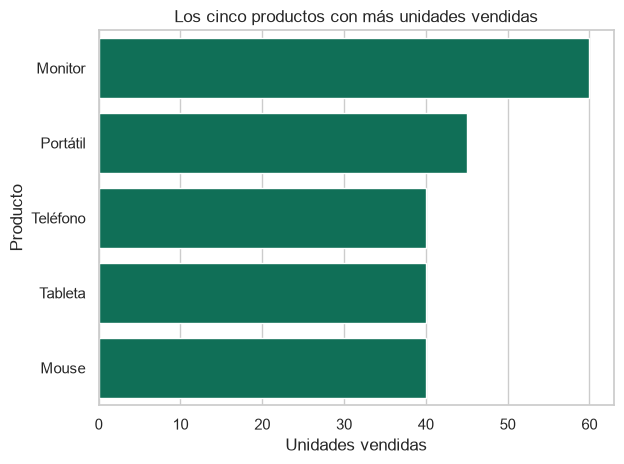

In [3]:
unidades_producto = ventas.groupby("producto")["unidades"].sum().sort_values(ascending=False)
display(unidades_producto.head(5))
sns.barplot(x=unidades_producto.head(5).values, y=unidades_producto.head(5).index, color="#007F5F")
plt.xlabel("Unidades vendidas")
plt.ylabel("Producto")
plt.title("Los cinco productos con más unidades vendidas")
plt.tight_layout()
plt.show()

## ¿Qué quedó de las ventas?
Las ventas netas descuentan las rebajas del precio. El costo de ventas (**COGS**, *cost of goods sold*) representa el costo de los productos efectivamente vendidos. La diferencia es la utilidad bruta.

| Indicador | Cálculo |
| --- | --- |
| Venta neta por fila | unidades × precio unitario × (1 − descuento / 100) |
| COGS por fila | unidades × costo unitario |
| Utilidad bruta | ventas netas − COGS |
| Margen bruto (%) | utilidad bruta total / ventas netas totales × 100 |
| COGS sobre ventas (%) | COGS total / ventas netas totales × 100 |

En este ejercicio, *sales turnover* se entiende como ingresos por ventas. **No es rotación de inventarios**: para calcular esa rotación necesitaríamos además el inventario promedio valorado al costo. El margen bruto tampoco es utilidad neta, porque aún faltan gastos operativos e impuestos.

**Completa las tres expresiones marcadas.** Sustituye `np.nan` por el cálculo que corresponde. `np.nan` solo indica que la respuesta está pendiente.

In [4]:
ventas["venta_neta"] = np.nan  # COMPLETAR: usa unidades, precio_unitario y descuento_pct
ventas["cogs"] = np.nan        # COMPLETAR: usa unidades y costo_unitario
ventas["utilidad_bruta"] = np.nan  # COMPLETAR: diferencia de las dos columnas anteriores

display(ventas[["producto", "venta_neta", "cogs", "utilidad_bruta"]].head())

,producto,venta_neta,cogs,utilidad_bruta
0,Cargador,NaN,NaN,NaN
1,Portátil,NaN,NaN,NaN
2,Mouse,NaN,NaN,NaN
3,Webcam,NaN,NaN,NaN
4,Router,NaN,NaN,NaN


La suma ya está preparada. Calcula el margen sobre los **totales**; promediar porcentajes por venta daría a ventas de distinto tamaño el mismo peso.

In [5]:
totales = ventas[["venta_neta", "cogs", "utilidad_bruta"]].sum(min_count=len(ventas))
margen_bruto_pct = np.nan   # COMPLETAR: utilidad bruta total / ventas netas totales × 100
cogs_sobre_ventas_pct = np.nan  # COMPLETAR: COGS total / ventas netas totales × 100

display(totales.to_frame("COP"))
print(f"Margen bruto: {margen_bruto_pct:.2f}%")
print(f"COGS sobre ventas: {cogs_sobre_ventas_pct:.2f}%")
if ventas[["venta_neta", "cogs", "utilidad_bruta"]].isna().any().any():
    print("Aún hay cálculos pendientes: completa la celda anterior.")
elif pd.isna(margen_bruto_pct) or pd.isna(cogs_sobre_ventas_pct):
    print("Falta completar los dos porcentajes.")
else:
    assert np.isclose(margen_bruto_pct + cogs_sobre_ventas_pct, 100), "Revisa los denominadores."
    print("Comprobación: ambos porcentajes suman 100 %.")

,COP
venta_neta,NaN
cogs,NaN
utilidad_bruta,NaN


Margen bruto: nan%
COGS sobre ventas: nan%
Aún hay cálculos pendientes: completa la celda anterior.


**Respuesta 1.** ¿Cuánto vendió Conecta y cuál fue su costo de ventas? Por cada 100 COP vendidos, ¿cuántos COP quedaron como utilidad bruta? ¿Podemos decir que ese valor es la ganancia neta?

Escribe tu respuesta con cifras: …

## ¿Dependemos de unos pocos productos?
La idea de Pareto invita a investigar si una parte pequeña del catálogo concentra gran parte de las ventas. **El 80/20 es una hipótesis que contrastamos, no un resultado obligatorio.**

La agrupación está resuelta. Completa el ordenamiento de mayor a menor venta y los porcentajes. Hay veinte productos, de modo que el 20 % corresponde exactamente a cuatro.

In [6]:
por_producto = ventas.groupby("producto", as_index=False).agg(
    venta_neta=("venta_neta", lambda s: s.sum(min_count=len(s))),
    utilidad_bruta=("utilidad_bruta", lambda s: s.sum(min_count=len(s)))
)
# COMPLETAR: ordena por venta_neta de mayor a menor con sort_values.
pareto = por_producto.copy()
pareto["participacion_pct"] = np.nan  # COMPLETAR: venta de cada producto / venta total × 100
pareto["acumulado_pct"] = np.nan      # COMPLETAR: aplica cumsum() a participacion_pct

display(pareto)
n_top = int(np.ceil(0.20 * len(pareto)))
print("Productos en el 20 % del catálogo:", n_top)

,producto,venta_neta,utilidad_bruta,participacion_pct,acumulado_pct
0,Adaptador,NaN,NaN,NaN,NaN
1,Alfombrilla,NaN,NaN,NaN,NaN
2,Audífonos,NaN,NaN,NaN,NaN
3,Cable HDMI,NaN,NaN,NaN,NaN
4,Cargador,NaN,NaN,NaN,NaN
5,Disco SSD,NaN,NaN,NaN,NaN
6,Funda,NaN,NaN,NaN,NaN
7,Hub USB,NaN,NaN,NaN,NaN
8,Limpiador,NaN,NaN,NaN,NaN
9,Memoria USB,NaN,NaN,NaN,NaN


Productos en el 20 % del catálogo: 4


El gráfico está preparado para utilizar tu tabla. La línea horizontal señala el 80 % de las ventas; la vertical, los primeros cuatro productos. El primer punto que alcanza o supera el 80 % indica cuántos productos necesitamos para llegar a ese umbral.

In [7]:
if pareto[["participacion_pct", "acumulado_pct"]].isna().any().any():
    print("Completa la tabla de Pareto para ver el gráfico.")
elif not pareto["venta_neta"].is_monotonic_decreasing:
    print("Ordena primero las ventas de mayor a menor.")
else:
    posiciones = np.arange(1, len(pareto) + 1)
    sns.lineplot(x=posiciones, y=pareto["acumulado_pct"].to_numpy(), marker="o")
    plt.axhline(80, linestyle="--", color="gray", label="80 % de ventas")
    plt.axvline(n_top, linestyle=":", color="darkorange", label="20 % de productos")
    plt.xticks(posiciones)
    plt.ylim(0, 105)
    plt.xlabel("Número de productos, ordenados por ventas")
    plt.ylabel("Ventas acumuladas (%)")
    plt.title("Concentración de las ventas")
    plt.legend()
    plt.tight_layout()
    plt.show()
    print(f"Los primeros {n_top} productos aportan {pareto.head(n_top)['participacion_pct'].sum():.2f}% de ventas.")
    necesarios = np.flatnonzero(pareto["acumulado_pct"].to_numpy() >= 80)[0] + 1
    print(f"Se necesitan {necesarios} productos para alcanzar al menos el 80%.")

Completa la tabla de Pareto para ver el gráfico.


**Respuesta 2.** Nombra los cuatro productos principales e indica qué porcentaje de ventas concentran. ¿Alcanzan el 80 %? ¿Cuál es la menor cantidad de productos que sí lo alcanza y qué porcentaje del catálogo representa?

Escribe tu respuesta con cifras: …

## Una decisión para el próximo mes
El producto que genera más ingresos no siempre deja la mayor utilidad bruta. Completa el ordenamiento siguiente para comprobarlo antes de recomendar una acción.

In [8]:
# COMPLETAR: ordena por utilidad_bruta de mayor a menor y conserva los primeros cinco.
ranking_utilidad = por_producto.copy()
display(ranking_utilidad)


,producto,venta_neta,utilidad_bruta
0,Adaptador,NaN,NaN
1,Alfombrilla,NaN,NaN
2,Audífonos,NaN,NaN
3,Cable HDMI,NaN,NaN
4,Cargador,NaN,NaN
5,Disco SSD,NaN,NaN
6,Funda,NaN,NaN
7,Hub USB,NaN,NaN
8,Limpiador,NaN,NaN
9,Memoria USB,NaN,NaN


**Respuesta 3.** ¿Coinciden el líder en ventas y el líder en utilidad bruta? Identifícalos con sus valores. Recomienda una acción concreta para el próximo mes apoyándote en **dos cifras** del análisis y señala **un dato adicional** que pedirías antes de ejecutarla.

Escribe tu recomendación: …

Una alta concentración puede justificar atención al abastecimiento de ciertos productos, pero no demuestra que debamos retirar los demás. El análisis tampoco mide demanda perdida, disponibilidad de inventario ni efecto de las promociones.

### Antes de entregar
Comprueba que completaste las expresiones, ejecutaste las celdas y respondiste las tres preguntas con unidades y porcentajes claros. Si compartes el archivo, conserva los resultados visibles.

### Referencias de las fórmulas
- [Utilidad bruta y margen bruto](https://www.accountingtools.com/articles/gross-margin)
- [Rotación de inventarios y el dato adicional que requiere](https://www.accountingcoach.com/blog/inventory-turnover-ratio-2)

El conjunto de datos fue creado para este ejercicio; no corresponde a una empresa real.